# MCDI503 | Evaluación Sumativa 1 — Fase 1
## EDA reproducible: supervivencia en el Titanic
**Universidad Andrés Bello · Magíster en Ciencia de Datos e Inteligencia Artificial**  
**Asignatura:** Exploración Inteligente para la Ciencia de Datos  
**Grupo 7:** Jorge Gutiérrez Jaramillo, Felipe Palma Barrientos y Cristian Grandón Grandón.  
**Docente:** Sergio Paraíso M. · **Fecha:** noviembre de 2026.  
**Dataset:** Titanic, colección de ejemplos de Seaborn ([fuente CSV](https://github.com/mwaskom/seaborn-data/blob/master/titanic.csv)). Unidad de observación: registro de pasajero.

**Propósito:** establecer una base reproducible para caracterizar la calidad de los datos y describir patrones de supervivencia.

## 1. Contexto, objetivo y preguntas exploratorias
El conjunto Titanic permite examinar características demográficas, económicas y familiares registradas para los pasajeros. Su diversidad de variables, valores ausentes y distribuciones heterogéneas justifica su elección frente a las alternativas del curso. El análisis permite reconocer restricciones de calidad y orientar decisiones de exploración posteriores (Paraíso, 2026; Tukey, 1977).

**Objetivo:** caracterizar estructura, calidad y distribución de los datos e identificar patrones descriptivos de supervivencia mediante un flujo trazable y reproducible.

| ID | Pregunta | Evidencia prevista |
|---|---|---|
| P1 | ¿Qué estructura, cobertura y problemas de calidad presenta el dataset? | Secciones 2, 3 y 7 |
| P2 | ¿Cuál es la proporción general de supervivencia? | Sección 4 |
| P3 | ¿Cómo varía la supervivencia por sexo, clase y familiares registrados? | Secciones 5 y 6 |
| P4 | ¿Cómo se distribuyen edad, tarifa y acompañantes familiares? | Secciones 4, 5 y 7 |
| P5 | ¿Qué asociaciones descriptivas se observan entre variables numéricas y grupos? | Sección 6 |

**Alcance:** exploración descriptiva inicial; no se imputan faltantes, no se ajustan modelos, no se realizan pruebas de hipótesis ni se infiere causalidad.

## 2. Entorno, carga y validación inicial (P1)
Esta variante autónoma para Canvas incorpora las mismas funciones del módulo `src/eda.py` y el mismo CSV del repositorio en formato gzip/Base64. La codificación es reversible y permite ejecutar el análisis sin archivos externos ni conexión a internet, previa instalación de las dependencias. La huella SHA-256 verifica la integridad de los bytes. Se registran las versiones efectivas de Python y de las bibliotecas.

In [1]:
# Funciones reutilizables (equivalentes a src/eda.py del repositorio).
"""Funciones reutilizables para el EDA descriptivo de Fase 1."""
from pathlib import Path
import hashlib
import pandas as pd

COLUMNAS = ['survived','pclass','sex','age','sibsp','parch','fare','embarked','class','who','adult_male','deck','embark_town','alive','alone']
NUMERICAS = ['age','fare','sibsp','parch']

def cargar_datos(ruta):
    df = pd.read_csv(ruta)
    assert list(df.columns) == COLUMNAS, 'Estructura inesperada'
    assert df.shape == (891,15), 'Dimensiones inesperadas'
    assert df.survived.notna().all() and df.survived.isin([0,1]).all()
    assert df.pclass.isin([1,2,3]).all()
    assert not df[['age','fare']].lt(0).any().any()
    df['class'] = pd.Categorical(df['class'], categories=['First','Second','Third'], ordered=True)
    df['deck'] = pd.Categorical(df['deck'], categories=list('ABCDEFG'))
    return df

def huella(ruta):
    return hashlib.sha256(ruta).hexdigest()

def calidad(df):
    return pd.DataFrame({'tipo':df.dtypes.astype(str),'nulos':df.isna().sum(),'porcentaje_nulos':(df.isna().mean()*100).round(2),'valores_unicos':df.nunique()}).sort_values('nulos',ascending=False)

def derivar(df):
    resultado = df.copy(deep=True)
    resultado['familia_a_bordo'] = resultado.sibsp + resultado.parch + 1
    resultado['viaja_solo'] = resultado.familia_a_bordo.eq(1)
    pd.testing.assert_frame_equal(resultado[df.columns],df)
    assert resultado.viaja_solo.eq(resultado.alone).all()
    return resultado

def resumen_grupo(df, columnas):
    return (df.groupby(columnas,dropna=False,observed=True)['survived'].agg(n='size',sobrevivientes='sum',tasa='mean').assign(tasa_pct=lambda x:(100*x.tasa).round(2)))

def frecuencias(serie):
    return pd.DataFrame({'n':serie.value_counts(dropna=False),'porcentaje':(serie.value_counts(dropna=False,normalize=True)*100).round(2)})

def outliers_iqr(serie):
    q1,q3 = serie.quantile([.25,.75]); iqr=q3-q1
    li,ls=q1-1.5*iqr,q3+1.5*iqr
    mask=serie.lt(li)|serie.gt(ls)
    return {'n_validos':int(serie.notna().sum()),'q1':q1,'q3':q3,'iqr':iqr,'limite_inferior':li,'limite_superior':ls,'n_atipicos':int(mask.sum()),'pct_validos':round(100*mask.sum()/serie.notna().sum(),2)}


In [2]:
# Copia local del CSV Titanic (Seaborn), comprimida y codificada para entrega autónoma.
# Fuente: https://github.com/mwaskom/seaborn-data/blob/master/titanic.csv
import base64, gzip, hashlib, io
DATOS_TITANIC = (
    'H4sIAAAAAAAC/71d2Y7dxhF9z7dcEKxe2OSjZ6zxs6C8B7I0iYTIkqElTv4+3Hov3q6qHhsGDCMZ8pLs7lpOnTr17cfX/3z8z/P7'
    '2+/vPr399u327fm/t7f/er59+/jrt99vv7/9+u7D7Z9vvz7fnn/79e3Xf69/ePzdHx++3N6+//Hp+z9+e/vp+fb++d2/zz/5x/cv'
    'f3y+vf203nX995fPz38bb/q2/5VSw3iD23hzg7K3N7e/f/j49f36f32+/f3rj+fb7c2XH98/vP3t9+9fPt8+f7k9vf307flvsF7x'
    'z+f9ej3762FQs9a3x9vTx6/fvt/++LLdZP/79X97/PD89dcvP77+6/a/52/hLtrfRU3rXcb9KZbkMdJ7ZE+y3WR7vuxJ7PkkVg+w'
    '3gJ7jPIex4OEj7HfYvtnfSnCx9ifIFx8XmjsrG+vq0tf/3h+/vxtX4d4JRxXWnP+rIVhnvb3Px4+XP7q/k9va6jXuykYRhcf/N2H'
    'j5/eY58vWci4BG5/CHUDGECvC0laBH8b5W8D5lwFPa7PMs7bR39+9+Vz8TSN/XDcZP1nGhz6Or9cPknYD3Y+v+q6uawlbojiu44d'
    '+0Ev+0vYm15PhiOfrTF+BTDhVMzWKNK6nqcirIf1Wxq2I/bGL0b7ZGWby2ybaxlg3ZuvsYfId3fcFPFggE5/Hv8G2W/7Uw3nfoJ5'
    'v0FjT2I7+/yEan34R+z6fC+eD6AKi6Cm9vOnn/+42i/gxdv/fGXU4hZILJJaVPPrZ4bxWD5/DNZXQSzLT80VmF/AuJxeYj8LenaW'
    'Y1xyA5uvY1yHuIiVeYVlfwO1ruGxDMUneKTuoNklK5A9ObYC5XPPi53JNuR8dOMN0GqdndqtafHwyIsnNvA4OWY1gOnF6aM/tEzx'
    '+fTOct783P+Td+sw7nuPdHrGbOduLzCrAVz75f128d/ORzZWYat+vej5ZluX/N5uQ+wlyJyGP/HbW6sugxd88OrKlQEXXqDpgpPn'
    '2LfedpNlMJQDmyyAymKK7R77N2k7n8wJVmeHcugTz6f331Y3A4N1+yoKApHddvSfflE8ua/gZrRb0eTLnFn/s+pYr8k1dj4asfgj'
    'C+v3Yu2Z89fdGWyswdM0s7xNff7SR2g57GAxzeLzmTX0PA5/bTR/vtg2ceP7uyh61FWYr+nw/HCbYFhc8iDhVR6wxQh+/47Pf7wK'
    'O+LzA2q4OVHjvF5ItKFY2HoeXrXv4jfo0W2EC7C9g90MwDQsoo2kwkZivEKeGe+Hf7OkqOtNv5v3Wj6LnfVpd2nRSnhq44Mdx3zr'
    'dN/wwo1osGAzWMo0jPX1kbm/5Z4aey4Y63mALQunHv5ovg7zozgwRLlpptN9z8M0KUbW51MGJQqZ4itM2K6nee3CfGreA8TXP4LO'
    'wWw5K8mDhC0U3t5Og2nHy4jZseHMTsjHfyJAOMxIXejmQ444DutO3b7+fgA4li7Nr3yeAIoWrSFfzn/6JQk72ycnP7vLYKlLhoQr'
    'My9gKRNc4xLcr/310zMvcXXp59e70d3DtVlmN+A4OHrDDDQPLRLuv+ColEbzYxZyqkwHUqaWnotHHCSjZtjeYK1hFjgK9IoZ/D1U'
    'WfePYOFszDCU/bOtTnht5638ut2mw05XwBAe3cQtswenetCbq60ub4bIJzYGx714IXIKrwEdnKvSlWA6Cpt/z12+GLZzOlq4uXXl'
    'Z2zr/dzYOlqHczNxtr6/3J2hSh7tUDfu1ccjR1tJojbxaj75x3fOsuME3fvwx74za6BJclklNuWdDo5NPTajPLP6KizMusA27iQ3'
    'MpRKRXRoVpaZ6Vee1xxVswY6X5t+QKuGxO3vxpChOkut2Klbkd8Dy/JA5i1X27duBIsmWg8NpEWdmUpRXKIkemmgr+iBfmfAkWY4'
    'Fq8QNnKE6DrUuXJw6TpeXZ3/vOTKN77B+IDqAVkvYLq7uw+qYGsNeLdfFkTcmydfTYC+OnZP95/c+DRrTTIdvzKqc+NLq+bU8Z7E'
    'cBkXE1TLgtdfBNxTRZpKKYvW1sd/v606eIAt909QGfGfQMkW8R+kjTcoyNlAKLXDCBdkoAqmkDQqmBw7fAqHYL2+aT/LbXAwHQqs'
    '6trv1GyJiA06buzibxGqNPKkcQnHkO3CwEdAq/2y7C0Iy8nQ0FMG0FLLa8rF78fEec7Pt+zeS5X5MsMBro9u/SnADuFT43qjeg6x'
    'hQjZWGXp3ALI9uCeuk7DJEvbrT09qSTzNuP5/TJTyoof3KBBsZNXC7E0otHSSOP0QqSbuY3qxK+S6bGfKUbDh4tL5/V7T8tBaOJ9'
    'cONDnvXtgc70U1lB+PQ6TlgUSr47P2wI+YLs04G4tBisVnCb43lkG3dAeWn7Guy0LOzIvrpzZP1CHCUik5d4KKlXVuKxZ9JEwUvr'
    'pJ8G0FdHdwq4k8Yqkw8NiyOmosWj75mFBcuRU1kU5p3eevlDsNqQ6Qh/CdBb3Mbz+QZUvLO0uzuXyw5mosRccef4wmxgJM2Dg52K'
    'dZ/vW+d/o8ht6uC0j6tHcpkiDftq88kojYWY29Ii7jG1G2eyrrmmR0XrpQ7rdVElemqXiYy3X2vkwLNfue2wI4Za/UTCzDJGSxsy'
    'g6wwXtN5qYDfSWcCDqOm3nRMtDBFLMYGYnH1/KoI9TmnpiQyQV0mIbK7E0YVFPEybQ9Ggo25oDTeYyWWoW/gdrO4jSh0T0+cdBb2'
    'w8b1H+kGuJ9SmeaNjL107cOX4a+MPwMZmhk5RMjJMhnAkPlMYrSO5Zp+xWFc3eaF4fyl9foKTffJCXOg0s5HoZxESr3IeRgbDyoq'
    '8s7IvxuzIIG/4YN2qfkMth+kTQxKUmV9kYjltLqOzuOEuvlh/WXlLIuMWHb28JurcqQDDps9MsAeqPyfmwa17GB5+0WuFoFBjIIK'
    'bORZAFWgVaINYKEXK2CGHXDLW/OWsV1kxNKcyAjSbFoTLIzlQjuvrPi8RmiTuVzeP2MpEqVEUPciFixOHqdmEaElquCVgOadl4SB'
    'y8pZsDKH6SMznm9PzNYKmyUihyROZ05qJFwKsuQQ1G5HR4RYOdH3wygCjCqHJGHLa+SSxS8dNvCxPj0m1G1mu9i+cZQ3m69rs3mV'
    'Knp3a9Fj29y5UIX4AVmnVxihKM7BxjCxR8J3t8CNLKAV06uyDioJu8RXl8qAO/0CvzRQzkndBwweCVsIjsZZEDTvGohgsQJlZa1c'
    'ykPOxFrlFeJclElb/a+pKwuVjmnAHdkDrTX/aHBXg77qqsEfRBXII0jK7p2EC93jCz3sqzxuuxx0NyrPtMy/0GDugehKCalf7Yem'
    'HkO+R95Y3YWc+dqAXNGYfldKABv2p709ocdj2D6G9b8mfUGceGxwj2IWTSWrl80NbewbO0DGl01hYXqVnPIxHhUYV4MAj614QoY/'
    'nFdP2m+ENZE9+ns4rJW8fkbnblTnIVkC3lFw/eWrM7GA3avISCOTxYAgGvaZcn4FjOOE8mO5PSawiDL4rOQ50csWKMl64gKPwXky'
    'GmOwEJhZdeDTU1CCkhIjhpWsz3xgnojTb8UOoXCxbPoTF6HDwwVdsfJgajiw01qJ4y5dLGlvma2gTSDBPyWtAuyezPjDmt+Gm1R7'
    '1dnbAhbSGDq1WI/XYEji7UZWHzLUMV9JlP6zNSwg74fXg2rYynv0vJHRUqeyh97i5e2HUYrzi+oOhAUbh0XxFv066YA1ZJyvVMEa'
    'iQcEpu44DwtDVyyHjM8+jZFMM68zHzutn+TC8rxqvEW0HPpoSqa8R/Up5pPsqNakVl/UAa5tYGqNgZ5AvVTLT4TkkgKy4pFGa504'
    'ehUbRVf6+NtBsW2XWuFTN7UHB2Ayw3zAzKKMJNIa9AYVUXboHZUDfvOl6yVGJI3LV4buwj6rggcLRQc1Cxhgl7XTxZzKrJB8xmNQ'
    'DqE4rrSTlEinJiugrTamIWYXlpdepNZqOp22dblyCc9n136X02Dn2QK7DgkZ+4OsOxABDHjdDZWME31THZ5vTT4mYtx8RziJ21mx'
    'YLzytlwaFEDDyDBKecxlbE+uF67G1W/uZ03qJThOynR01KvC18pahLoajC6MCdkYEShKT224ahRy5qoCVgrgk0yZzvluYClSOlib'
    'nOpirIc+r2WvYkmSRm15/cVRdPKgGGdJI7252GIyYNzCEblwJ+e1ld00Qmq+qjSfmNy8Xq3JF9OqPOPJoreAKl4UOyMDVkHJuWps'
    'FthV61rD2f0FmntowVmw+SafqTo7KCHNC4N52un2C2HzweKvQbTmUXpzi7GePmMAqS000pigPEhll15hNRI1FaWuMoCW4Uq0KoUa'
    'u3nEWEqlEsrEGN7LpAnCLZcQV3tPKa08VDd2r1sJuLYfJFypNGQNZAHl9tSHDlhlrUVnqd7JBAEiTZLRWIRK4KsLH/ZnpA0l604k'
    'HCcUa+RlwI2Ci99AqdB2gyCAyIipFGuk4J3x6XfUVREK/EiwmjSlOZFy3ixRAyplxPrJyoH6lEr/X/N+7iNajtdokKNzdJSxRjon'
    'gWw8ou/AojqrStZq3YsTW9MuDi+gWqI7jb5CdSHoUBfKtcNZ3RalwBGSutH3QFQnAwl9zgLGUqAOHvCZ6yyWz03tiROsoZBE/WJa'
    'nNO67tRJLKkL1Slp/jWK3NznvXLpIVA06AvOXBrCZyeOQzrVfujKLq/EI52qrFK1m2+5qt/Yx96H0UehuzqbQPhZrk0EuK4EkVyT'
    'as1LrKbvDN9yZ8mRC63lJWX1z6L8lj5LVJRLd9+Cul1BCMhmiN6X03t1zXTIPTaJq/yCSKfKEiBhUbTU5+BR9j0/dowIwEKmx6Zl'
    'J4NG0Om5f2iTA09VvEpXiKcQdrQQ6NL/svT/jUfiWFNrohmFviDSWLxYzxJDH+WdxizaL7oIc0f9IPWnAIqhag23TGphhiMOwbbj'
    'TwSLplHOLlFxJu+7ZgknFJ1g6ngEleoFEuaopNx3Ng8sL0ch0yDIbmm3jcuwMCVP8nDk+PEWqFXsAg+Iz8sAIyaz/EiQiGSxuJBg'
    'YiHMYyhkehpiG69aSNRhyYtxhhSedt3w0TGEhO3N/bLNnNdH1MFMB5gctIE1Sl141UAe5q5edfGww1lSdRET6kspJYppu2qtdooR'
    '7J1bc9z2lMgmdrXHFXNlOEXlNNHTuDnlBYwRpNKDO1r6Uc7RBeuprDksw6x53RiZIJHiMPtfBqBRUVFnF2Fl66dHmHJnNvP1031o'
    'oLyEMZ+hsEhnJPX2wliBgGLy7lOkRtjZcScG5wFm2ViAasiiycILCgVkGg00opA3gsFZoT1ZD/cACy1chbB3uugxsrisxloEyaZl'
    'BKTXwzPW8M6iUR0JJBLLgZR6+UTV59DP7eZBbZ+cXqApft9SOqKrXhKLN5Ncb3Zk0Y20tNOpIFqPrGB10pYsi0kR2DlYZcoxzR4m'
    '/j0JG7rjQN0Z7cxotYHmAUgtvMyRN+hQAoxYm8pIztTEapKNKMMyM0foKXqhrh6dhMr4wINX7W4sb0DsMhg6xQQ7vRLt2JgYrfc5'
    'IqbWzAa0xtE3ZPD4iNngFypHQE/dGKsW9oTWTU2L5p7+rrZUKbuzVo6U9BWM3LHOV2LnPDjhJaCMzOCt/sdtb84WM1lEisUpH0Ed'
    'oslWIqXUJtWTZ79z1w0czmWmSsV7vVxNGFCE5ghaSiRIvp/rkKIiyuc+kA0HjKvjYzDkqthVTs5We8TN6icqu7TUEb3TDF+1mIt8'
    '6lKsT4P0JpANiaUqM2EpY9A2KtayRdVMa1PXigrNkZtLT6032Uv6wJfvsswRdFbjXW4EexaE4ZDRJ5yaDPgTXTVINwsDpSQlj2FW'
    'MBwYTEdsKDZfhTbl5jkRybgl69Vk+vrkZdMjQk3JTxdfPvfEOU2YOhN8QUWgKF0maZvmFNtrjEgDRqx9PXY1gKclWfuXFCfkzKg8'
    'a1Eh6Bc3FrDD5VwCzpTNAXwuHWOKPZJutPV+si6+/LCyVGDTlFOfH9/CYNLIl9onXyW/mpf89om2C9SHr1sbWKETkvKyaRCl2Sq4'
    'OcyxNVGMlDTq82oyPIscmeYgns+iRwHoVNrvu8ImDddtjch1l3t5tcWAeaC702POXeiAn34Haiffd8XqtEsmF3J0M9IuOSCM/LvX'
    'FtAxsktQGLcCUlxqAFU/aG+cTOIjTYGpgHfJQnNdGrI6SNZwfG8poqSlDUFmEQ0bkuJcOWWoVB26HLVwRT+EQq7/L5KPOIyT2iNT'
    'Fh/DGEkxEopzdqQF9+JyJCOcYreIZLLJKAVl81QOL0a2PZtXaTMw2AMXbXef4UpCh2lmiaRWJapj/9oS3uCHqxJegEyxvDMr0lay'
    'cUs9KnWw7mRlAYNR/xndThMmds3iPBvxgLKYHnYJDatksnMmHdDUe8sJ8GzBdMjozicjIusAvrJC15QGibpquJymWH41mHFT6KYX'
    '12JU63AlL2rjVXx5lrrv5YDRjtoUvXcn7J55jDa8yUSrnztp9hvpKx+dX8avbgbGiL8eyThugYbrg0co7NkWc/T7WubzJgm+ImEt'
    '828reXOOv5OMGcgbLFgWo1+3o5iNJtoE6ZkTcCm6mbg52xuO4VQOjbgb+ZUM4oN6IKwdLHeyWj0ih84f1ZGAyoPiO2ZTlZ2icDyG'
    'rL0oMulMOsuXHi0iZRASqpe/w9ZsLBmsEJBlomLGi3RIpxPZqnmo9MQ+pX8LiPuhTbjQirgS5C4bikavrpgrJLYroHUhgz8gKJTe'
    'rGfhEXs06nGyhnN28jCTDoWWmIySbbs+acEixOKPfzdaBg9kHUmKybIu9QihynBY4zMA0+e55mAUX96NwpbOoiGUMw+gn+kfdYEk'
    'q67MybuS9QlA1ASct4yM5+X8yh+EgSnvkqDx/NMDD/X8I0avwdmMqhmepoaYyCFONY5RokTpd4Dp7DKZ8KPHslgoQNaUJYzPj40w'
    'YmhKpKMAd4U27jecJcz3tHzjlRU3cTatnWV1yENtwhxXpiobQr8plg8GJscJ2DtShrEaoiTw/NMo6jdURRe0iP0gQ8er8nUKbRBC'
    '3bwoAUS+Ur39TUzTJ+Tpn5q7N8iD3NHne7yf56UlAhYFvo74O/RJ0/GQm0diasRMIfajJfxl7LcIas+lKkS9hxltd0b1NyJEvc3r'
    'VqKWtsOZ+2RDFe/jtBhsUnaAERT/CR0sj/cBgwBY4GEkfbDwMpiZnDejdkwQDi59lkDPBKXOx8YsyTjQ+5KP/4oCfpCkgi/mifGU'
    'SsOj+1AyL2pzuPRhsA4VbC5tiOnRlrejSFseiiKP1Ttc2jQdV4CpuHl+3PHOsmmcKCtfOmMem0wVjctsTkVOhSoBBFbjcrAhVTjJ'
    '6SWCkJPOgzsms7Wk5nuz0j78qu/q2IFo+YU6XTCYtUSiqgyF6AlpL/TbhRoXs+RGSnEWoc1BNYqQMdUkKINJhnClXGJutSdyIEEm'
    'EAkJfLTT54CFPqUk1nr0KJ2LpUdxsQ9ueeMIbv1/bvF0gD35tCA4QFWvIHV9+CFPUbDDXKAITQemdYekmu6c1nVaHgFTJaCQ47Cm'
    '/CdTRapMO8tEAEqdcmI3Y7+0UykvK2u+F3bRxRQcREzUutLcbCNAKeS4vjm1/y6n0QtF/i10DZDOnFDaPEQd8oC2EFPUH2IBg9Z4'
    'ftU0Pg9aMobIyE2OEQ6Mjp3T3Eytn4irCr0D3VGiTmFbK6UjIQv+1BAos5GMZajSUBdcKI56XlowQbFmynlPyzcatzp3sOLLMbIZ'
    'YE2zO1DgJZTQEzu3attBhk8sVj2zjFKgu6dyVhSpGfyQuWPefRgKsn+99exzBc6gmMTQ7hnhnL+7vA6YhL25Hh6op5FS2GRFkjQd'
    'sp8cZSrb1d0ZsGUusuOtxhJ5FXvnA4MBCsj0jnmYUnSTQypkBDu4o8e6Vihr2AOxpakWiMWbY486iPW0wwEeB7OzdNa1sLJaX0Bq'
    'p2Fx/EEkWjbFAoodPXLkJTET6pxohEjniQrDLLJ8mdq3WTGqZ34IE+tNtAau4v2tsCEgwcrFch15zC5R8r3eOg/Npm+NQj2MreMt'
    'wNaBd1SoWJyHwLaaSIFLAeuOUlJw2fcIHJ2qK9NBwvoRyHC+d/qb7FqHoz2809dPPPHGk1unYpAsKqqZn4RX7T0mx4OhkJcO0wzp'
    '7rZw6M7B5/fZiwYiwlMHdGvWvYOXxFJXKbwnaB+CqCutBcCWZ4jMq6s5ePjtqd/XfG7JuGSxkG3AR9htCFktH5XffaTx6kTdKzCJ'
    '+KC1pNfuLNh6XtpTM9evpp0V6LLJ1zrhE1n+RqnzK3Krr6WPVbiSvylr9/QRi+goCYryhI5DSfriIWf6psIlmtEZ86Y1WrzWr92d'
    'omFCuCrTkmRIkGHSgIELtmwNj6yxS1BN2YHJDPOhg02e2hrbIUA0r6Ieu6mrNiq6uqtcWhN8M8eaI4yz5o8dhzB5lKVPmWuCCZGH'
    'ftxGFTC7MOc3Siz0k/Oi4JTWO7YBVUogb3LYvenovSk5cY4baRnYbjz0wMMAaTsYq7Y4derrGq83WraRs2pMoUxoedlj3p+0kFVL'
    '0EF8hjjIuDaMOMW6Bdpj3QazEai8Ly/RBC5bfuud070w+LEp4BK4+nKhaN0rO5dKtwFxvsWV3J9Iz0FY/EgTkr3tJK8+MFocXR/6'
    'BmjZiFjrjxFfWTxi0LyCNdufgJmbJJ311ArI/wGFXbiVut4AAA=='
)
bytes_csv = gzip.decompress(base64.b64decode(DATOS_TITANIC))
assert hashlib.sha256(bytes_csv).hexdigest() == '81787d320d7f7b03df935e91de8bd19e11d45c5bbcab86ef4d4a76dc91b7d4f2'
print('Integridad del dataset verificada:', hashlib.sha256(bytes_csv).hexdigest())

Integridad del dataset verificada: 81787d320d7f7b03df935e91de8bd19e11d45c5bbcab86ef4d4a76dc91b7d4f2


In [3]:
import sys, platform
from importlib.metadata import version
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

sns.set_theme(style='whitegrid', context='notebook')
print('Python:',sys.version.split()[0], '| SO:',platform.system())
for paquete in ['numpy','pandas','seaborn','matplotlib','ipykernel']:
    print(paquete,version(paquete))
titanic = cargar_datos(io.BytesIO(bytes_csv))
print('Fuente: Seaborn, CSV incorporado | SHA-256:',huella(bytes_csv))
print('Dimensiones:',titanic.shape)
display(titanic.head(8))
titanic.info()

Python: 3.14.8 | SO: Windows
numpy 2.5.5
pandas 2.3.3
seaborn 0.13.2
matplotlib 3.11.2
ipykernel 7.4.0
Fuente: Seaborn, CSV incorporado | SHA-256: 81787d320d7f7b03df935e91de8bd19e11d45c5bbcab86ef4d4a76dc91b7d4f2
Dimensiones: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True
7,0,3,male,2.0,3,1,21.0750,S,Third,child,False,NaN,Southampton,no,False


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


**Resultado y decisión.** Se cargan 891 registros y 15 variables; los controles verifican estructura, codificación binaria de supervivencia y ausencia de edades o tarifas negativas. Se conserva el objeto original como referencia. Las variables categóricas `class` y `deck` reciben categorías explícitas para mantener su semántica.

## 3. Diagnóstico de calidad (P1)
Se cuantifica cobertura, cardinalidad, duplicados y consistencia básica antes de transformar los datos.

,tipo,nulos,porcentaje_nulos,valores_unicos
deck,category,688,77.22,7
age,float64,177,19.87,88
embarked,object,2,0.22,3
embark_town,object,2,0.22,3
sex,object,0,0.00,2
pclass,int64,0,0.00,3
survived,int64,0,0.00,2
fare,float64,0,0.00,248
parch,int64,0,0.00,7
sibsp,int64,0,0.00,7


Filas duplicadas posteriores a la primera aparición: 107
Edades y tarifas negativas: {'age': 0, 'fare': 0}


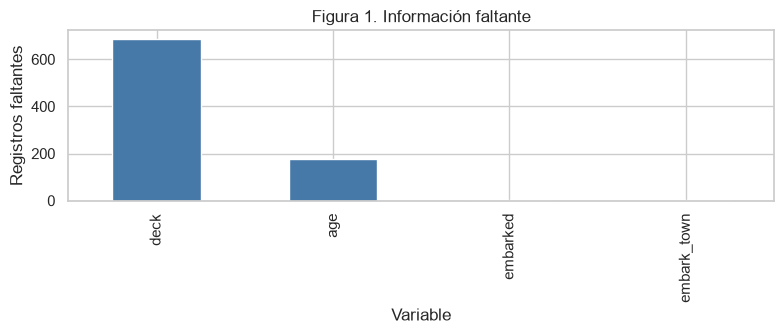

In [4]:
diagnostico = calidad(titanic)
display(diagnostico)
print('Filas duplicadas posteriores a la primera aparición:',titanic.duplicated().sum())
print('Edades y tarifas negativas:',titanic[['age','fare']].lt(0).sum().to_dict())
ax=diagnostico.loc[diagnostico.nulos.gt(0),'nulos'].plot.bar(figsize=(8,3.5),color='#4779a8')
ax.set(title='Figura 1. Información faltante',xlabel='Variable',ylabel='Registros faltantes'); plt.tight_layout(); plt.show()

**Resultado y decisión.** `deck` presenta 688 nulos (77,22 %), `age` 177 (19,87 %), y `embarked` y `embark_town` dos cada una (0,22 %). Se conservan los faltantes: no se ha estudiado su mecanismo de ausencia. Se detectan 107 filas duplicadas posteriores a la primera ocurrencia; sin identificador único no es posible confirmar que sean el mismo pasajero. Se mantienen los 891 registros y se documenta la restricción.

## 4. Estadísticas descriptivas y distribuciones (P2, P4)
Se utilizan frecuencias, medias, medianas, cuartiles y gráficos para reconocer patrones y tamaños desiguales de los grupos.

,age,fare,sibsp,parch
count,714.00,891.00,891.00,891.00
mean,29.70,32.20,0.52,0.38
std,14.53,49.69,1.10,0.81
min,0.42,0.00,0.00,0.00
25%,20.12,7.91,0.00,0.00
50%,28.00,14.45,0.00,0.00
75%,38.00,31.00,1.00,0.00
max,80.00,512.33,8.00,6.00


survived


,n,porcentaje
survived,,
0,549,61.62
1,342,38.38


sex


,n,porcentaje
sex,,
male,577,64.76
female,314,35.24


pclass


,n,porcentaje
pclass,,
3,491,55.11
1,216,24.24
2,184,20.65


embarked


,n,porcentaje
embarked,,
S,644,72.28
C,168,18.86
Q,77,8.64
NaN,2,0.22


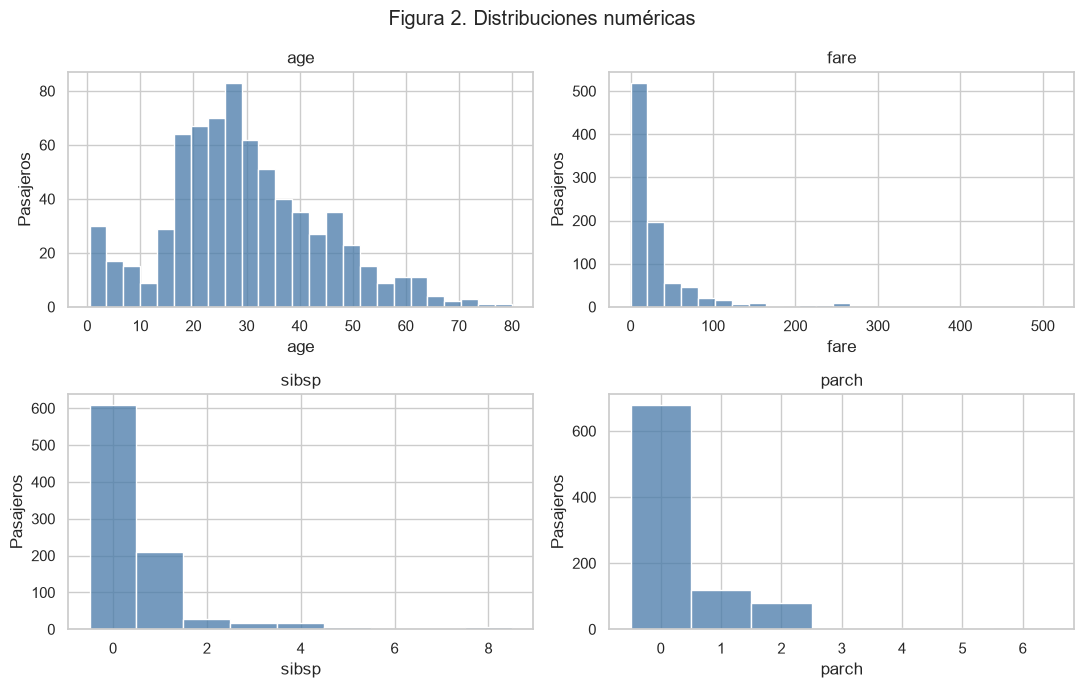

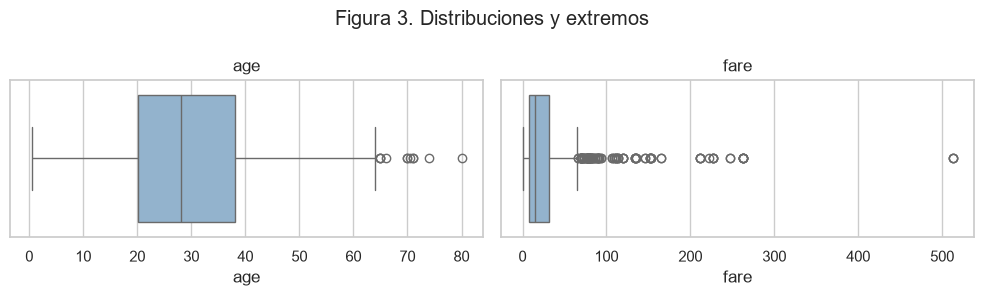

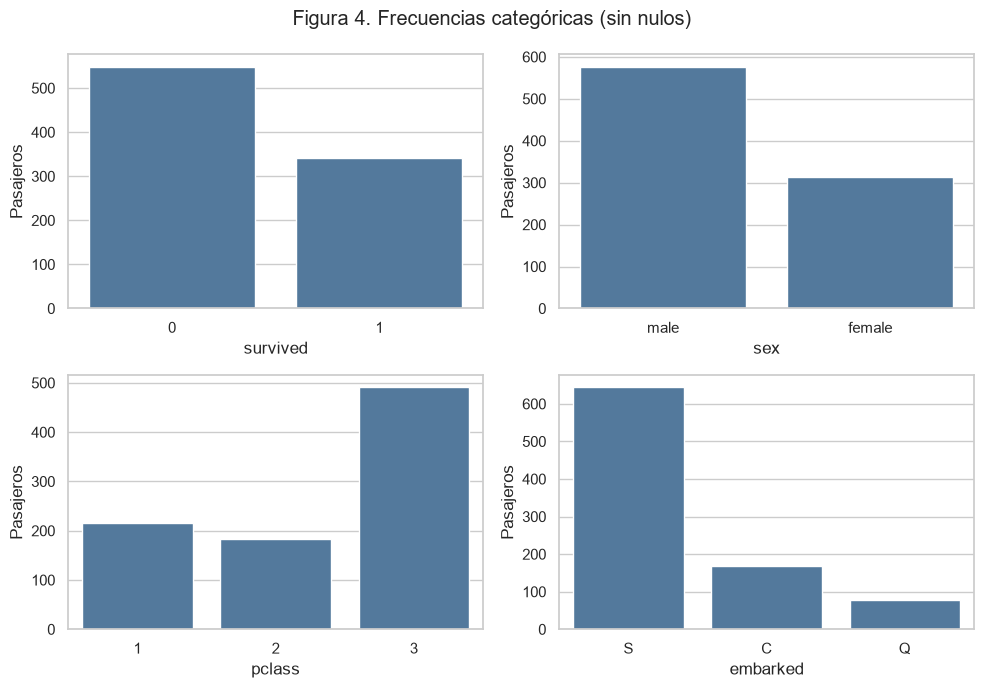

In [5]:
display(titanic[NUMERICAS].describe().round(2))
for variable in ['survived','sex','pclass','embarked']:
    print(variable); display(frecuencias(titanic[variable]))
fig,axes=plt.subplots(2,2,figsize=(11,7))
for ax,var in zip(axes.flat,NUMERICAS):
    sns.histplot(data=titanic,x=var,discrete=var in ['sibsp','parch'],bins=25,ax=ax,color='#4779a8')
    ax.set(title=var,ylabel='Pasajeros')
fig.suptitle('Figura 2. Distribuciones numéricas');plt.tight_layout();plt.show()
fig,axes=plt.subplots(1,2,figsize=(10,3))
for ax,var in zip(axes,['age','fare']):
    sns.boxplot(data=titanic,x=var,ax=ax,color='#89b4d7');ax.set_title(var)
fig.suptitle('Figura 3. Distribuciones y extremos');plt.tight_layout();plt.show()
fig,axes=plt.subplots(2,2,figsize=(10,7))
for ax,var,orden in zip(axes.flat,['survived','sex','pclass','embarked'],[[0,1],['male','female'],[1,2,3],['S','C','Q']]):
    sns.countplot(data=titanic,x=var,order=orden,ax=ax,color='#4779a8');ax.set_ylabel('Pasajeros')
fig.suptitle('Figura 4. Frecuencias categóricas (sin nulos)');plt.tight_layout();plt.show()

**Resultado y decisión.** Sobreviven 342 de 891 pasajeros (38,38 %). La edad tiene 714 registros válidos, media 29,70 y mediana 28 años. La tarifa presenta media 32,20, mediana 14,45 y asimetría positiva; se priorizan mediana y cuartiles para describir su centro. Las variables familiares concentran frecuencias en cero. El 64,76 % de los registros son hombres y el 55,11 % corresponde a tercera clase; por ello se compararán proporciones dentro de cada grupo y no solo conteos absolutos.

## 5. Transformaciones iniciales (P3, P4)
Se construyen dos variables a partir de los acompañantes familiares registrados, sin alterar las columnas originales. `familia_a_bordo = sibsp + parch + 1` incluye al propio pasajero; `viaja_solo` indica ausencia de esos familiares.

In [6]:
df=derivar(titanic)
print('Dimensiones originales y finales:',titanic.shape,df.shape)
print('Coincidencia con alone:',df.viaja_solo.eq(df.alone).sum(),'/',len(df))
display(df[['sibsp','parch','familia_a_bordo','viaja_solo']].head(10))
display(df.familia_a_bordo.value_counts().sort_index().rename('pasajeros').to_frame())

Dimensiones originales y finales: (891, 15) (891, 17)
Coincidencia con alone: 891 / 891


,sibsp,parch,familia_a_bordo,viaja_solo
0,1,0,2,False
1,1,0,2,False
2,0,0,1,True
3,1,0,2,False
4,0,0,1,True
5,0,0,1,True
6,0,0,1,True
7,3,1,5,False
8,0,2,3,False
9,1,0,2,False


,pasajeros
familia_a_bordo,
1,537
2,161
3,102
4,29
5,15
6,22
7,12
8,6
11,7


**Resultado y decisión.** Se conservan 891 filas y se incorporan dos columnas (17 en total). La igualdad de todas las columnas originales se verifica programáticamente. `viaja_solo` coincide con `alone` en los 891 casos. Hay 537 pasajeros sin familiares registrados y 354 con al menos uno; estas variables no identifican familias únicas ni acompañantes de otro tipo.

## 6. Relaciones y comparaciones descriptivas (P3, P5)
Se calculan tasas dentro de cada grupo, se explora conjuntamente sexo y clase, y se examinan las asociaciones lineales y las diferencias de edad y tarifa. Las comparaciones de edad excluyen registros sin esa información.

sex


,n,sobrevivientes,tasa,tasa_pct
sex,,,,
female,314,233,0.742038,74.20
male,577,109,0.188908,18.89


pclass


,n,sobrevivientes,tasa,tasa_pct
pclass,,,,
1,216,136,0.629630,62.96
2,184,87,0.472826,47.28
3,491,119,0.242363,24.24


viaja_solo


,n,sobrevivientes,tasa,tasa_pct
viaja_solo,,,,
False,354,179,0.505650,50.56
True,537,163,0.303538,30.35


n  sobrevivientes      tasa  tasa_pct
sex    pclass                                         
female 1        94              91  0.968085     96.81
       2        76              70  0.921053     92.11
       3       144              72  0.500000     50.00
male   1       122              45  0.368852     36.89
       2       108              17  0.157407     15.74
       3       347              47  0.135447     13.54

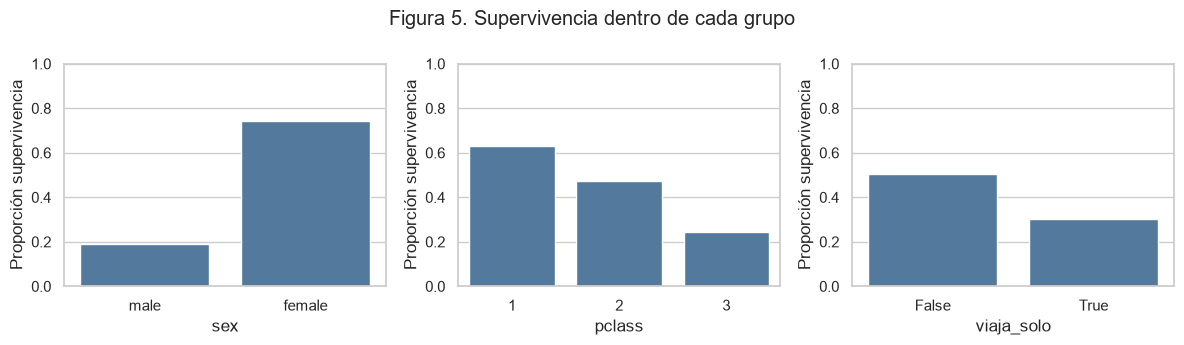

In [7]:
for variable in ['sex','pclass','viaja_solo']:
    print(variable);display(resumen_grupo(df,variable))
display(resumen_grupo(df,['sex','pclass']))
fig,axes=plt.subplots(1,3,figsize=(12,3.5))
for ax,var in zip(axes,['sex','pclass','viaja_solo']):
    sns.barplot(data=df,x=var,y='survived',errorbar=None,ax=ax,color='#4779a8');ax.set(ylim=(0,1),ylabel='Proporción supervivencia')
fig.suptitle('Figura 5. Supervivencia dentro de cada grupo');plt.tight_layout();plt.show()

**Resultado.** La supervivencia alcanza 74,20 % en mujeres y 18,89 % en hombres; 62,96 %, 47,28 % y 24,24 % en primera, segunda y tercera clase. Entre quienes registran familiares es 50,56 %, frente a 30,35 % sin familiares registrados. La diferencia por sexo persiste dentro de cada clase, aunque varía su magnitud. No se controlan factores de confusión, por lo que las diferencias son descriptivas.

,age,fare,sibsp,parch
age,1.000,0.096,-0.308,-0.189
fare,0.096,1.000,0.160,0.216
sibsp,-0.308,0.160,1.000,0.415
parch,-0.189,0.216,0.415,1.000


,age,fare,sibsp,parch
age,714,714,714,714
fare,714,891,891,891
sibsp,714,891,891,891
parch,714,891,891,891


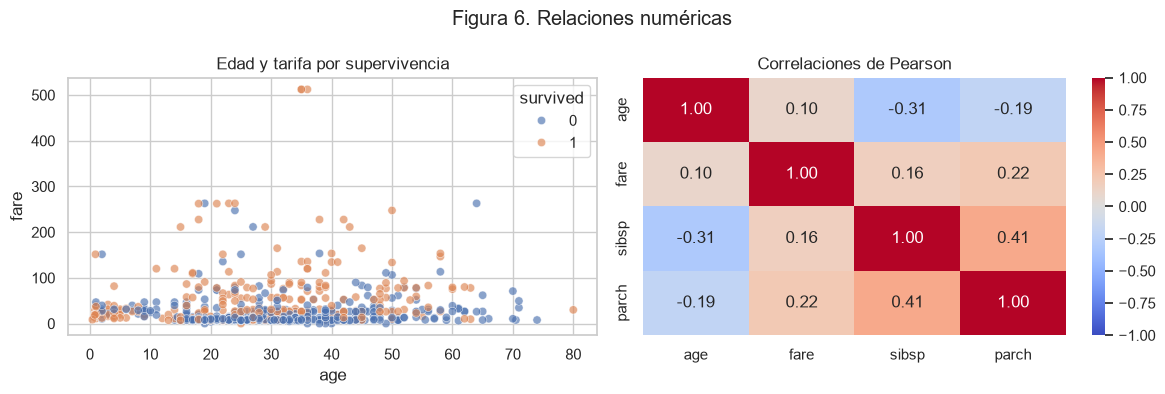

survived


age                fare              
         count   mean median count   mean median
survived                                        
0          424  30.63   28.0   549  22.12   10.5
1          290  28.34   28.0   342  48.40   26.0

sex


age                fare              
       count   mean median count   mean median
sex                                           
female   261  27.92   27.0   314  44.48   23.0
male     453  30.73   29.0   577  25.52   10.5

pclass


age                fare              
       count   mean median count   mean median
pclass                                        
1        186  38.23   37.0   216  84.15  60.29
2        173  29.88   29.0   184  20.66  14.25
3        355  25.14   24.0   491  13.68   8.05

embarked


age                fare              
         count   mean median count   mean median
embarked                                        
C          130  30.81   29.0   168  59.95  29.70
Q           28  28.09   27.0    77  13.28   7.75
S          554  29.45   28.0   644  27.08  13.00
NaN          2  50.00   50.0     2  80.00  80.00

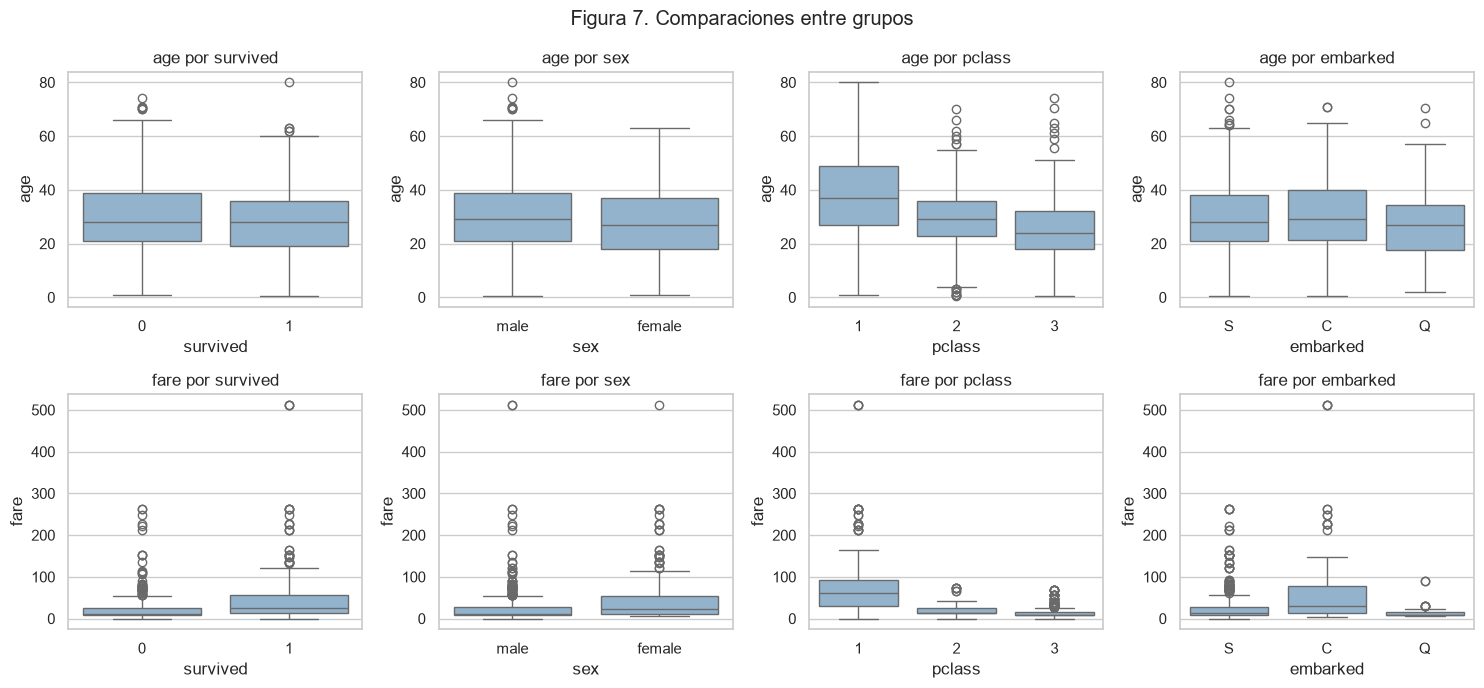

In [8]:
corr=df[NUMERICAS].corr()
pares=df[NUMERICAS].notna().astype(int).T @ df[NUMERICAS].notna().astype(int)
display(corr.round(3));display(pares)
fig,axes=plt.subplots(1,2,figsize=(12,4))
sns.scatterplot(data=df,x='age',y='fare',hue='survived',alpha=.65,ax=axes[0]);axes[0].set_title('Edad y tarifa por supervivencia')
sns.heatmap(corr,annot=True,fmt='.2f',cmap='coolwarm',vmin=-1,vmax=1,ax=axes[1]);axes[1].set_title('Correlaciones de Pearson')
fig.suptitle('Figura 6. Relaciones numéricas');plt.tight_layout();plt.show()
for variable in ['survived','sex','pclass','embarked']:
    print(variable);display(df.groupby(variable,observed=True,dropna=False)[['age','fare']].agg(['count','mean','median']).round(2))
fig,axes=plt.subplots(2,4,figsize=(15,7))
for j,var in enumerate(['survived','sex','pclass','embarked']):
    for i,num in enumerate(['age','fare']):
        sns.boxplot(data=df,x=var,y=num,ax=axes[i,j],color='#89b4d7');axes[i,j].set_title(f'{num} por {var}')
fig.suptitle('Figura 7. Comparaciones entre grupos');plt.tight_layout();plt.show()

**Resultado y decisión.** La asociación lineal más destacada entre las variables seleccionadas es `sibsp`–`parch` (r = 0,415); edad y tarifa presentan asociación lineal débil (r = 0,096). Las correlaciones con edad utilizan 714 pares válidos; las restantes, 891. La tarifa media de sobrevivientes es 48,40 frente a 22,12 en no sobrevivientes; las edades medias son 28,34 y 30,63 años, respectivamente. Las diferencias y los coeficientes no demuestran causalidad ni descartan asociaciones no lineales.

## 7. Valores potencialmente atípicos (P1, P4)
Se aplica la regla de 1,5 veces el rango intercuartílico (Tukey, 1977). Se considera el número de registros válidos como denominador de cada proporción.

In [9]:
atipicos=pd.DataFrame({v:outliers_iqr(df[v]) for v in ['age','fare']}).T
display(atipicos.round(4))

,n_validos,q1,q3,iqr,limite_inferior,limite_superior,n_atipicos,pct_validos
age,714.0,20.1250,38.0,17.8750,-6.6875,64.8125,11.0,1.54
fare,891.0,7.9104,31.0,23.0896,-26.7240,65.6344,116.0,13.02


**Resultado y decisión.** Se identifican 11 edades (1,54 % de 714) y 116 tarifas (13,02 % de 891) potencialmente atípicas. Se conservan porque el criterio IQR no permite confirmar errores. La mayor frecuencia de extremos en tarifa refuerza el uso de mediana y cuartiles.

## 8. Síntesis de resultados y trazabilidad
La siguiente evidencia computacional responde explícitamente a las cinco preguntas iniciales.

In [10]:
print('P1 | Dimensiones:',titanic.shape,'| Duplicados:',titanic.duplicated().sum())
display(diagnostico.loc[diagnostico.nulos.gt(0),['nulos','porcentaje_nulos']])
print(f'P2 | Supervivencia: {df.survived.sum()}/{len(df)} = {df.survived.mean():.2%}')
print('P3 | Tasas dentro de cada grupo:')
for v in ['sex','pclass','viaja_solo']:
    display(resumen_grupo(df,v)[['n','tasa_pct']])
print('P4 | Distribuciones:');display(df[NUMERICAS].describe().round(2));display(df.familia_a_bordo.value_counts().sort_index().rename('pasajeros').to_frame())
print('P5 | Asociaciones:');display(corr.round(3));display(df.groupby('survived')[['age','fare']].mean().round(2))
print('Transformación verificada:',titanic.shape,'->',df.shape)

P1 | Dimensiones: (891, 15) | Duplicados: 107


,nulos,porcentaje_nulos
deck,688,77.22
age,177,19.87
embarked,2,0.22
embark_town,2,0.22


P2 | Supervivencia: 342/891 = 38.38%
P3 | Tasas dentro de cada grupo:


,n,tasa_pct
sex,,
female,314,74.20
male,577,18.89


,n,tasa_pct
pclass,,
1,216,62.96
2,184,47.28
3,491,24.24


,n,tasa_pct
viaja_solo,,
False,354,50.56
True,537,30.35


... (3 outputs left out)

P5 | Asociaciones:


,age,fare,sibsp,parch
age,1.000,0.096,-0.308,-0.189
fare,0.096,1.000,0.160,0.216
sibsp,-0.308,0.160,1.000,0.415
parch,-0.189,0.216,0.415,1.000


,age,fare
survived,,
0,30.63,22.12
1,28.34,48.40


Transformación verificada: (891, 15) -> (891, 17)


### Registro consolidado de decisiones
| Sección / pregunta | Decisión | Justificación | Resultado intermedio |
|---|---|---|---|
| 2 / P1 | CSV local y validaciones | Evitar dependencia de red y comprobar estructura | 891 × 15; huella registrada |
| 3 / P1 | Conservar duplicados y nulos | Falta identificador y mecanismo de ausencia | 891 filas; cobertura documentada |
| 4 / P2, P4 | Usar mediana y cuartiles | Asimetría de tarifa | Mediana 14,45; media 32,20 |
| 5 / P3, P4 | Derivar variables sobre copia | Preservar entrada y explorar familia | 891 × 17; coincidencia con `alone` 100 % |
| 6 / P3, P5 | Comparar tasas internas y pares válidos | Tamaños desiguales y edad incompleta | Tasas por grupo; 714 pares con edad |
| 7 / P1, P4 | Conservar extremos IQR | No hay evidencia de error | 11 edades y 116 tarifas señaladas |

### Supuestos, limitaciones y cierre
Se asume que las codificaciones documentadas representan los atributos registrados; la fila es la unidad de observación. No se presume que la muestra sea representativa de todos los pasajeros ni que los datos ausentes sean aleatorios. No se puede distinguir duplicación real sin identificador, ni identificar familias únicas. Las comparaciones se restringen a datos disponibles y no ajustan confusión. Se identifican asociaciones de supervivencia con sexo, clase y composición familiar, junto con restricciones de cobertura y asimetría en tarifa. La fase siguiente deberá profundizar en el mecanismo de ausencia, la sensibilidad a extremos y el análisis conjunto de variables.

### Referencias
- Paraíso, S. (2026). *Resumen aplicado del libro: EDA mínimo viable* [Apunte de curso]. Universidad Andrés Bello. (Referencia registrada en el README original; verificar datos bibliográficos con el material docente.)
- Tukey, J. W. (1977). *Exploratory data analysis*. Addison-Wesley.
- Waskom, M. L. (2021). seaborn: Statistical data visualization. *Journal of Open Source Software, 6*(60), 3021. https://doi.org/10.21105/joss.03021
- Waskom, M. (s. f.). *titanic.csv* [Conjunto de datos]. GitHub. https://github.com/mwaskom/seaborn-data/blob/master/titanic.csv
- The pandas development team. (s. f.). *pandas documentation*. https://pandas.pydata.org/docs/